In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt

def A_hat(m: int, rho: float) -> float:
    """Fourier cosine coefficient hatA(m) for the band kernel at bandwidth rho."""
    if m == 0:
        return 1.0
    x = 2 * math.pi * m * rho
    if abs(x) < 1e-12:
        return 1.0  # numerical safeguard (limit as x->0)
    return math.sin(x) / x

# ======== EDIT YOUR PARAMETERS HERE ========
r = 0.1        # logistic growth rate
eta_n = 0.05
n0 = 8.0
eta_c = 0.04
k = 7
alpha = 0.2
beta = 0.1
rho = 0.10     # bandwidth of the band kernel

# new reaction
theta = 1.1/n0
# ==========================================

c0 = alpha*n0/beta

# Fourier coefficients
A0  = A_hat(0, rho)
Ak  = A_hat(k, rho)
A2k = A_hat(2*k, rho)

# Useful combinations
Delta  = A0 - Ak
Delta2 = A0 - A2k
C2     = A0 - 2*Ak + A2k
Delta_extreme = A0

# Logistic derivatives at n0
# f(n) = r*n(1 - n/n0)  
fp   = -r          # f'(S)
fpp  = 2*r*(theta - 1/n0)      # f''(S)
fppp = 3*r*theta*(2/n0 - theta)         # f'''(S)

# w
num_w = eta_n*eta_c*(Delta**2) + (beta*eta_n - 2*eta_c*fp)*Delta - 2*beta*fp
den_w = alpha*eta_n*Delta*n0
if abs(den_w) < 1e-14:
    raise ZeroDivisionError("alpha*eta_n*Delta is too small; adjust rho or parameters.")
w_star = num_w / den_w

num_w_extreme = eta_n*eta_c*(Delta_extreme**2) + (beta*eta_n - 2*eta_c*fp)*Delta_extreme - 2*beta*fp
den_w_extreme = alpha*eta_n*Delta_extreme*n0
if abs(den_w_extreme) < 1e-14:
    raise ZeroDivisionError("alpha*eta_n*Delta is too small; adjust rho or parameters.")
w_star_w_extreme = num_w_extreme / den_w_extreme

print(w_star)
print(w_star_w_extreme)

0.3984580819264639
0.43749999999999994


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


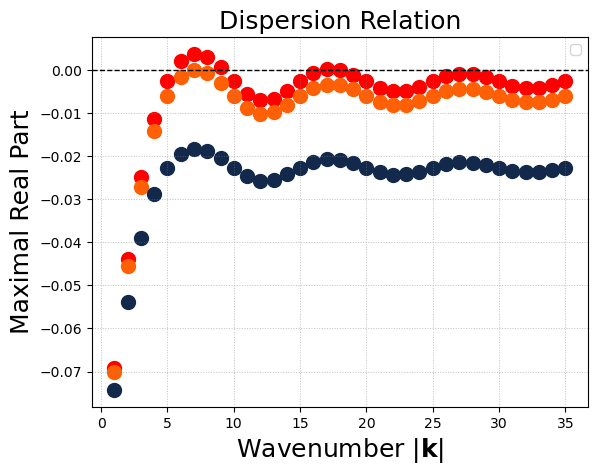

In [2]:
def L(w, Delta):
    return np.array([[-eta_n*Delta/2 + fp, eta_n*w*n0*Delta/2], [alpha, -eta_c*Delta - beta]])

w_small = 0.3
w_large = 0.42

k_intervals = np.linspace(1, 20, 10000)
k_discrete = np.arange(1, 36) 
eig_greater = np.zeros(len(k_discrete))
eig_star = np.zeros(len(k_discrete))
eig_smaller = np.zeros(len(k_discrete))

for i in range(len(k_discrete)):
    eigvals = np.linalg.eigvals(L(w_large, A_hat(0, rho) - A_hat(k_discrete[i], rho)))
    eig_greater[i] = np.max(np.real(eigvals))
    eigvals = np.linalg.eigvals(L(w_star, A_hat(0, rho) - A_hat(k_discrete[i], rho)))
    eig_star[i] = np.max(np.real(eigvals))
    eigvals = np.linalg.eigvals(L(w_small, A_hat(0, rho) - A_hat(k_discrete[i], rho)))
    eig_smaller[i] = np.max(np.real(eigvals))


max_reals = []
max_reals_small = []
max_reals_large = []

for ks in k_intervals:
    eigvals = np.linalg.eigvals(L(w_star, A_hat(0, rho) - A_hat(ks, rho)))
    max_real = np.max(np.real(eigvals))
    max_reals.append(max_real)
    eigvals = np.linalg.eigvals(L(w_small, A_hat(0, rho) - A_hat(ks, rho)))
    max_real = np.max(np.real(eigvals))
    max_reals_small.append(max_real)
    eigvals = np.linalg.eigvals(L(w_large, A_hat(0, rho) - A_hat(ks, rho)))
    max_real = np.max(np.real(eigvals))
    max_reals_large.append(max_real)

max_real_parts = np.array(max_reals)
max_real_parts_small = np.array(max_reals_small)
max_real_parts_large = np.array(max_reals_large)

#plt.plot(k_intervals, max_real_parts_large, label = "$w>w^{*}(k)$", color = "red", linewidth = 1.5)
plt.scatter(k_discrete, eig_greater, s=100, alpha=1, color = "red")

#plt.plot(k_intervals, max_real_parts, label = "$w=w^{*}(k)$", color = "#FF5F05", linewidth = 1.5)
plt.scatter(k_discrete, eig_star, s=100, alpha=1, color = "#FF5F05")

#plt.plot(k_intervals, max_real_parts_small, label = "$w<w^{*}(k)$", color = "#13294B", linewidth = 1.5)
plt.scatter(k_discrete, eig_smaller, s=100, alpha=1, color = "#13294B")

plt.axhline(y=0, color='k', linestyle='--', linewidth = 1)  
plt.grid(True)
plt.grid(which = 'both')
plt.grid(alpha = 0.5)
plt.grid(color = 'gray', linestyle = ':', linewidth = 0.7) 
plt.legend()
plt.xlabel('Wavenumber $|\\mathbf{k}|$', fontsize=18)
plt.ylabel('Maximal Real Part', fontsize=18)
plt.title('Dispersion Relation', fontsize=18)
#plt.savefig("dispersion_relation.pdf", format="pdf", bbox_inches="tight")
plt.show()

In [3]:
k = 7
w = 0.3984580819264639
print(np.linalg.eigvals(L(w, A_hat(0, rho) - A_hat(k, rho))))

[ 0.         -0.27905535]


In [4]:
# p and q
q_n = 1.0
q_c = alpha/(beta + eta_c*Delta)
q = np.array([[q_n], [q_c]])

p_n = (2*alpha*beta + 2*alpha*eta_c*Delta)/(alpha*(eta_n + 2*eta_c)*Delta + 2*alpha*(beta - fp))
p_c = ((beta + eta_c*Delta)*(eta_n*Delta - 2*fp))/(alpha*(eta_n + 2*eta_c)*Delta + 2*alpha*(beta - fp))
#p_n = 2*alpha/(eta_n*Delta - 2*fp)
#p_c = 1.0

p = np.array([[p_n], [p_c]])

ip = (p.T @ q).item()

print("p          = ", p)
print("q          = ", q)
print("p·q        = ", ip)
print("L(k)q      = ", L(w_star, Delta) @ q)
print("p^TL(k)    = ", p.T @ L(w_star, Delta))

p          =  [[0.53268804]
 [0.34732833]]
q          =  [[1.        ]
 [1.34544731]]
p·q        =  0.9999999999999999
L(k)q      =  [[1.23189474e-17]
 [2.72223324e-18]]
p^TL(k)    =  [[3.85611907e-18 3.59415325e-18]]


In [5]:
# s_0, s_2, t_0 and t_2
s_0n = - fpp*q_n**2/4
s_0c = 0.0

s_2n = -eta_n*w*q_n*q_c*Delta2/8 - fpp*q_n**2/4
s_2c = 0.0

s_0 = np.array([[s_0n], [s_0c]])
s_2 = np.array([[s_2n], [s_2c]])

L_0 = np.array([[fp, 0], [alpha, -beta]])
L_2k = np.array([[-eta_n*Delta2/2 + fp, eta_n*w*n0*Delta2/2], [alpha, -eta_c*Delta2 - beta]])
L_0_inv = np.linalg.inv(L_0)
L_2k_inv = np.linalg.inv(L_2k)

t_0 = L_0_inv @ s_0
t_2 = L_2k_inv @ s_2

t_0n = t_0[0][0]
t_0c = t_0[1][0]
t_2n = t_2[0][0]
t_2c = t_2[1][0]

print("t_0n       = ", t_0n)
print("t_0c       = ", t_0c)
print("t_2n       = ", t_2n)
print("t_2c       = ", t_2c)

t_0n       =  0.0062500000000000056
t_0c       =  0.012500000000000011
t_2n       =  0.24972113877705873
t_2c       =  0.3636878739410164


In [6]:
# kappa
kappa = (n0/2.0)*eta_n*p_n*q_c*(A0 - Ak)

# T1, T2, T3, gamma
#T1 = -(eta_n*w/8) * p_n * (q_n*t_2c + q_c*t_2n) * (A0 - A2k)
#T2 = (w**3 * n0 / 32.0) * p_n * (q_c**3) * (-3*A0 + 4*Ak - A2k)
#T3 = fpp * p_n * q_n * (t_0n + 0.5*t_2n)
#T4 = 0.0
T1 = (eta_n/2)*w*p_n*q_c*t_0n*Delta
T2 = (eta_n/8)*w*p_n*q_c*t_2n*(A0 + A2k - 2*Ak)
T3 = (eta_n/8)*w*p_n*q_n*t_2c*(A0 - A2k)
T4 = (eta_n/32)*w**3*n0*p_n*q_c**3*(4*Ak - A2k - 3*A0)
T5 = fpp*p_n*q_n*(t_0n + t_2n/2) + fppp*p_n*q_n**3/8
gamma = T1 + T2 + T3 + T4 + T5

print("kappa      = ", kappa)
print("gamma      = ", gamma)

kappa      =  0.17433619427681338
gamma      =  -0.0023774828528576072
